In [4]:
# !pip install numpy
# !pip install pandas
# !pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 1.5 MB/s  0:00:07 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 1.5 MB/s  0:00:03 eta 0:00:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 1.3 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 1.2 MB/s  0:00:05 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
item_master_df = pd.read_csv("../data/item_master.csv")
promo_calendar_df = pd.read_csv("../data/promo_calendar.csv")
sales_history_df = pd.read_csv("../data/sales_history.csv")
stock_history_df = pd.read_csv("../data/stock_history.csv")

In [3]:
item_master_df.head()

,sku,category,abc_class,launch_period,predecessor_sku,uom
0,SKU_0001,SNACK,B,2023-01,NaN,PCS
1,SKU_0002,DAIRY,C,2023-01,NaN,PCS
2,SKU_0003,HOUSEHOLD,A,2023-01,NaN,PCS
3,SKU_0004,BEVERAGE,B,2023-01,NaN,PCS
4,SKU_0005,SNACK,C,2023-01,NaN,PCS


In [4]:
promo_calendar_df

,sku,period,promo_type,discount_pct
0,SKU_0001,2023-11,TPR,25
1,SKU_0001,2024-11,TPR,25
2,SKU_0006,2024-03,TPR,25
3,SKU_0013,2025-04,TPR,25
4,SKU_0020,2023-06,TPR,25
5,SKU_0023,2025-10,TPR,25
6,SKU_0028,2023-12,TPR,25
7,SKU_0037,2024-08,TPR,25


In [5]:
stock_history_df.head()

,sku,location,period,stock_end_qty,days_out_of_stock
0,SKU_0001,MSK,2023-01,174,0
1,SKU_0001,MSK,2023-02,150,0
2,SKU_0001,MSK,2023-03,193,0
3,SKU_0001,MSK,2023-04,232,0
4,SKU_0001,MSK,2023-05,199,0


In [6]:
sales_history_df.head()

,sku,location,period,qty
0,SKU_0001,MSK,2023-01,243
1,SKU_0001,MSK,2023-02,179
2,SKU_0001,MSK,2023-03,168
3,SKU_0001,MSK,2023-04,204
4,SKU_0001,MSK,2023-05,153


In [7]:
KEY = ['sku', 'location', 'period']
dfs = {'sales': sales_history_df, 'stock': stock_history_df,
       'promo': promo_calendar_df, 'items': item_master_df}

audit = pd.DataFrame({
    n: {'строк': len(d),
        'пропусков': int(d.isna().sum().sum()),
        'полных дублей': int(d.duplicated().sum())}
    for n, d in dfs.items()
}).T
display(audit)

for n in ['sales', 'stock']:
    d = dfs[n]
    by_key, full = d.duplicated(KEY).sum(), d.duplicated().sum()
    print(f'{n}: дублей по ключу = {by_key}, из них с разными значениями = {by_key - full}')

sales_keys = set(map(tuple, sales_history_df[KEY].drop_duplicates().values))
stock_keys = set(map(tuple, stock_history_df[KEY].values))
print('ключи sales и stock совпадают:', sales_keys == stock_keys)
print('sku в sales без записи в справочнике:', set(sales_history_df.sku) - set(item_master_df.sku))
print('sku в promo без записи в справочнике:', set(promo_calendar_df.sku) - set(item_master_df.sku))
print('predecessor вне справочника:', set(item_master_df.predecessor_sku.dropna()) - set(item_master_df.sku))

,строк,пропусков,полных дублей
sales,1526,0,3
stock,1523,0,0
promo,8,0,0
items,40,39,0


sales: дублей по ключу = 3, из них с разными значениями = 0
stock: дублей по ключу = 0, из них с разными значениями = 0
ключи sales и stock совпадают: True
sku в sales без записи в справочнике: set()
sku в promo без записи в справочнике: set()
predecessor вне справочника: set()


рядов: 46
пустых ячеек: 133


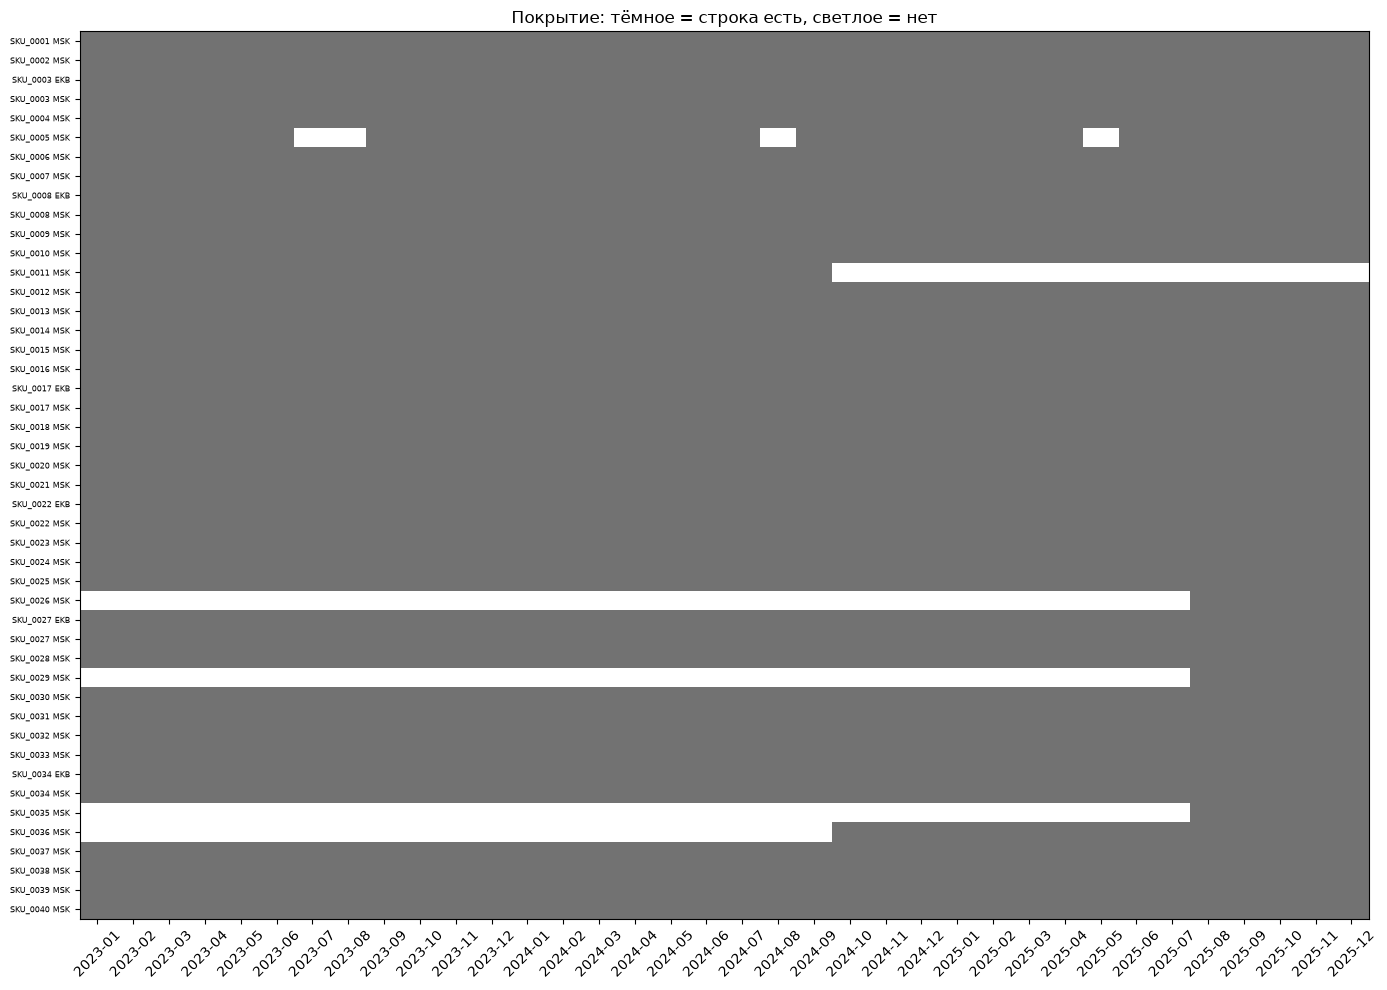

In [8]:
all_periods = pd.period_range('2023-01', '2025-12', freq='M').astype(str)

cov = (sales_history_df.drop_duplicates(KEY).assign(v=1)
       .pivot_table(index=['sku', 'location'], columns='period', values='v', aggfunc='sum')
       .reindex(columns=all_periods))

print('рядов:', len(cov))
print('пустых ячеек:', int(cov.isna().sum().sum()))

fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(cov.notna().astype(int).values, aspect='auto', cmap='Greys',
          vmin=0, vmax=1.6, interpolation='nearest')
ax.set_yticks(range(len(cov)))
ax.set_yticklabels([f'{a} {b}' for a, b in cov.index], fontsize=6)
ax.set_xticks(range(0, 36))
ax.set_xticklabels(all_periods, rotation=45)
ax.set_title('Покрытие: тёмное = строка есть, светлое = нет')
plt.tight_layout(); plt.show()

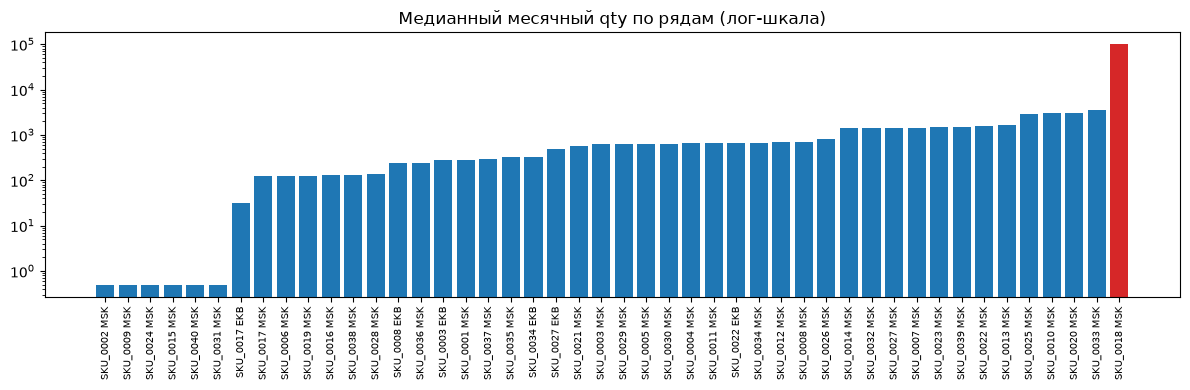

In [9]:
sales = sales_history_df.drop_duplicates().copy()
sales['date'] = pd.to_datetime(sales['period'])
sales['series'] = sales['sku'] + ' ' + sales['location']
sales = sales.sort_values(['series', 'date']).reset_index(drop=True)

lvl = sales.groupby('series').qty.median().sort_values()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(lvl)), lvl.values.clip(min=0.5),
       color=['tab:red' if v > 20000 else 'tab:blue' for v in lvl.values])
ax.set_yscale('log')
ax.set_xticks(range(len(lvl))); ax.set_xticklabels(lvl.index, rotation=90, fontsize=7)
ax.set_title('Медианный месячный qty по рядам (лог-шкала)')
plt.tight_layout(); plt.show()

,series,period,qty,log_jump
719,SKU_0018 MSK,2024-07,400250,7.091702


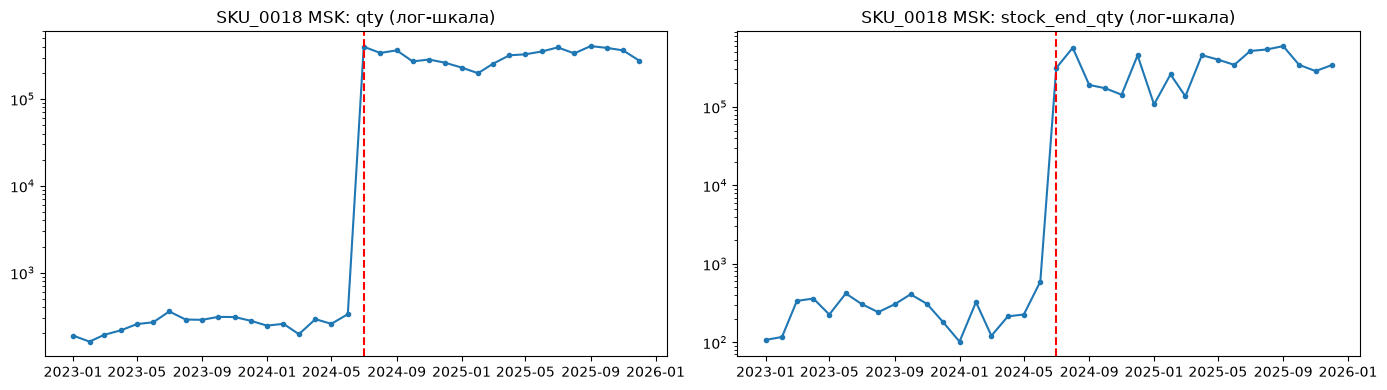

медианы до/после: 263.5 331304.0 | отношение: 1257
диапазоны до: 161 358 | после: 198363 406748


In [41]:
pos = sales['qty'].where(sales['qty'] > 0)
sales['log_jump'] = np.log(pos).groupby(sales['series']).diff()
display(sales.loc[sales.log_jump.abs() > np.log(10), ['series', 'period', 'qty', 'log_jump']])

x = sales[sales.series == 'SKU_0018 MSK'].merge(stock_history_df, on=['sku', 'location', 'period'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['qty', 'stock_end_qty']):
    ax.plot(x.date, x[col], marker='o', ms=3)
    ax.axvline(pd.Timestamp('2024-07-01'), color='red', ls='--')
    ax.set_yscale('log'); ax.set_title(f'SKU_0018 MSK: {col} (лог-шкала)')
plt.tight_layout(); plt.show()

before, after = x[x.date < '2024-07-01'], x[x.date >= '2024-07-01']
print('медианы до/после:', before.qty.median(), after.qty.median(),
      '| отношение:', round(after.qty.median() / before.qty.median()))
print('диапазоны до:', before.qty.min(), before.qty.max(), '| после:', after.qty.min(), after.qty.max())

In [49]:
def fix_scale(df, sku, break_period, factor, cols):
    out = df.copy()
    m = (out.sku == sku) & (out.period >= break_period)
    out.loc[m, cols] = (out.loc[m, cols] / factor).round()
    return out

for f in (1000, 1257):
    y = fix_scale(x, 'SKU_0018', '2024-07', f, ['qty'])
    ratio = y[y.date >= '2024-07-01'].qty.iloc[:6].mean() / y[y.date < '2024-07-01'].qty.iloc[-6:].mean()
    print(f'фактор {f}: уровень после / до (по 6 мес.) = {ratio:.2f}')

фактор 1000: уровень после / до (по 6 мес.) = 1.21
фактор 1257: уровень после / до (по 6 мес.) = 0.97


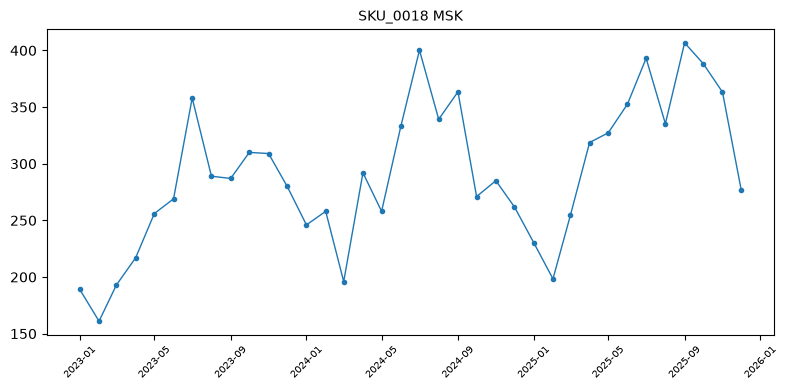

In [62]:
sales['qty_fixed'] = sales['qty'].astype(float)

SCALE_FACTOR = 1000

mask = (sales.sku == 'SKU_0018') & (sales.period >= '2024-07')
sales.loc[mask, 'qty_fixed'] = sales.loc[mask, 'qty'] / SCALE_FACTOR

fig, ax = plt.subplots(figsize=(8, 4))
sname = "SKU_0018 MSK"
q = sales[sales.series == sname]
ax.plot(q.date, q.qty_fixed, marker='o', ms=3, lw=1)
ax.set_title(sname, fontsize=10); ax.tick_params(axis='x', rotation=45, labelsize=7)
plt.tight_layout(); plt.show()

In [54]:
display(sales[sales.qty < 0][['series', 'period', 'qty']])

,series,period,qty
538,SKU_0014 MSK,2024-06,-8


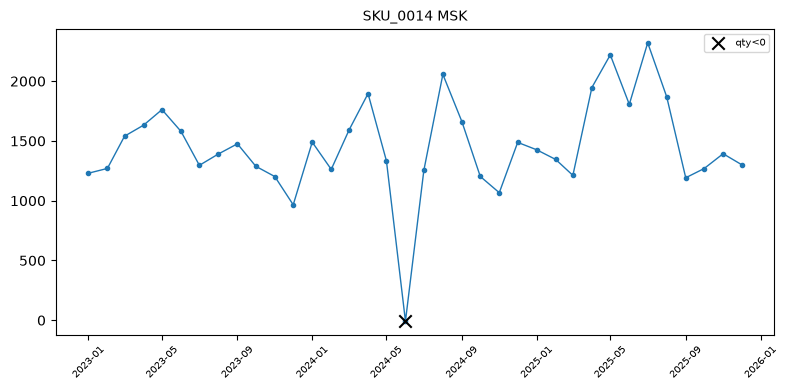

In [55]:
fig, ax = plt.subplots(figsize=(8, 4))
sname = "SKU_0014 MSK"
q = sales[sales.series == sname]
ax.plot(q.date, q.qty_fixed, marker='o', ms=3, lw=1)
neg = q[q.qty_fixed < 0]
ax.scatter(neg.date, neg.qty_fixed, color='black', marker='x', s=80, zorder=3, label='qty<0')
ax.set_title(sname, fontsize=10); ax.tick_params(axis='x', rotation=45, labelsize=7)
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [52]:
d = sales[sales.qty_fixed > 0].copy()
d['lq'] = np.log(d.qty_fixed)
g = d.groupby('series').lq
d['z'] = (d.lq - g.transform('median')) / (1.4826 * g.transform(lambda v: (v - v.median()).abs().median()))
d['n_obs'] = d.groupby('series').qty.transform('size')
d = d.merge(promo_calendar_df[['sku', 'period']].assign(promo=True), on=['sku', 'period'], how='left')
d['promo'] = d['promo'].fillna(False).astype(bool)

out = d[d.z.abs() > 3.5][['series', 'period', 'qty_fixed', 'z', 'promo', 'n_obs']].sort_values('z')
display(out)

,series,period,qty_fixed,z,promo,n_obs
915,SKU_0026 MSK,2025-12,654.0,-15.093446,False,5
160,SKU_0005 MSK,2023-10,297.0,-5.294042,False,32
1350,SKU_0040 MSK,2023-12,18.0,-4.774818,False,12
199,SKU_0006 MSK,2024-03,476.0,4.631715,True,36
863,SKU_0023 MSK,2025-10,5279.0,4.987953,True,36
1260,SKU_0037 MSK,2024-08,1345.0,5.391849,True,36
22,SKU_0001 MSK,2024-11,1159.0,5.835163,True,36
10,SKU_0001 MSK,2023-11,1172.0,5.881270,True,36
454,SKU_0013 MSK,2025-04,7202.0,6.160671,True,36
692,SKU_0020 MSK,2023-06,15629.0,6.443676,True,36


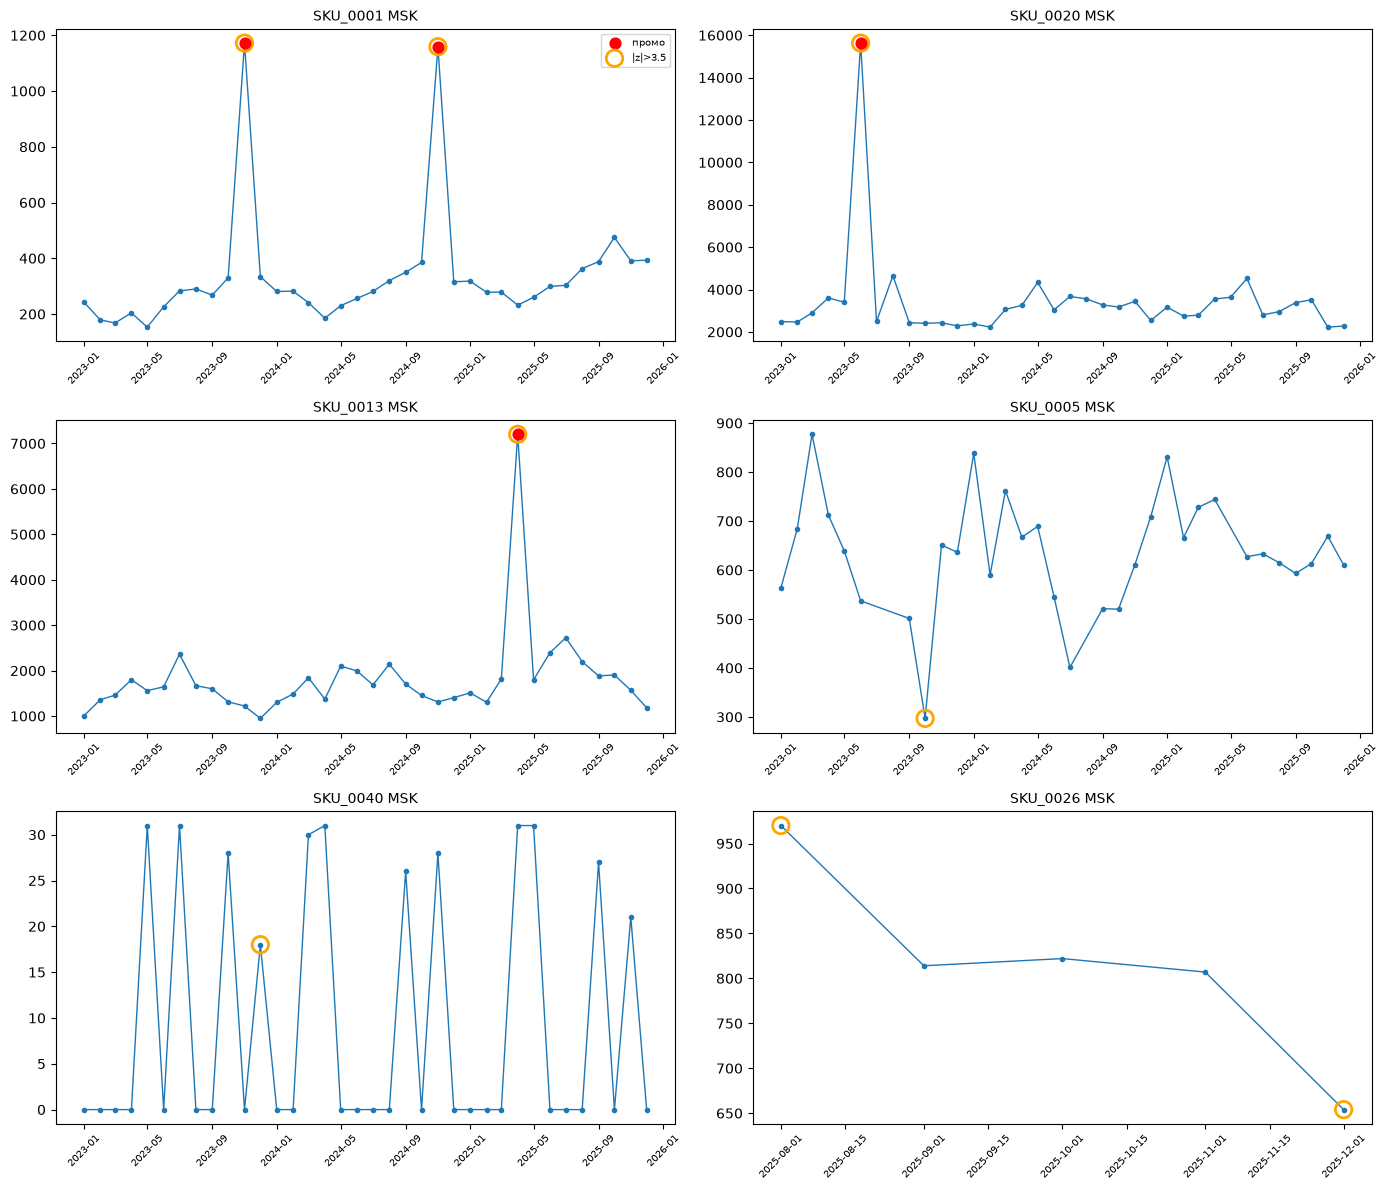

In [53]:
flag = ['SKU_0001 MSK', 'SKU_0020 MSK', 'SKU_0013 MSK',
        'SKU_0005 MSK', 'SKU_0040 MSK', 'SKU_0026 MSK']
promo_pts = promo_calendar_df.assign(series=lambda t: t.sku + ' MSK', date=lambda t: pd.to_datetime(t.period))

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, sname in zip(axes.ravel(), flag):
    q = sales[sales.series == sname]
    ax.plot(q.date, q.qty_fixed, marker='o', ms=3, lw=1)
    p = promo_pts[promo_pts.series == sname].merge(q[['date', 'qty_fixed']], on='date')
    ax.scatter(p.date, p.qty_fixed, color='red', s=60, zorder=3, label='промо')
    o = out[out.series == sname].merge(q[['period', 'date']], on='period')
    ax.scatter(o.date, o.qty_fixed, facecolors='none', edgecolors='orange', s=140, lw=2, zorder=2, label='|z|>3.5')
    ax.set_title(sname, fontsize=10); ax.tick_params(axis='x', rotation=45, labelsize=7)
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [64]:
KEY = ['sku', 'location', 'period']
m = sales.merge(stock_history_df, on=KEY, how='left', validate='one_to_one')

print(m.days_out_of_stock.value_counts().sort_index())
display(pd.crosstab([m.qty_fixed.eq(0).rename('qty=0'), m.stock_fixed.eq(0).rename('stock_end=0')],
                    m.days_out_of_stock.gt(0).rename('days_oos>0')))

days_out_of_stock
0     1513
30      10
Name: count, dtype: int64


days_oos>0         False  True 
qty=0 stock_end=0              
False False         1360      0
True  False          142      0
      True            11     10

In [65]:
oos = m[m.days_out_of_stock > 0][['series', 'period', 'qty_fixed', 'stock_fixed', 'days_out_of_stock']]
display(oos)

z = m[(m.qty_fixed == 0) & (m.stock_fixed == 0) & (m.days_out_of_stock == 0)]
print(z.series.value_counts())

,series,period,qty_fixed,stock_fixed,days_out_of_stock
256,SKU_0007 MSK,2023-09,0.0,0.0,30
257,SKU_0007 MSK,2023-10,0.0,0.0,30
469,SKU_0012 MSK,2024-09,0.0,0.0,30
470,SKU_0012 MSK,2024-10,0.0,0.0,30
471,SKU_0012 MSK,2024-11,0.0,0.0,30
839,SKU_0021 MSK,2025-07,0.0,0.0,30
1265,SKU_0033 MSK,2024-03,0.0,0.0,30
1266,SKU_0033 MSK,2024-04,0.0,0.0,30
1440,SKU_0038 MSK,2025-02,0.0,0.0,30
1441,SKU_0038 MSK,2025-03,0.0,0.0,30


series
SKU_0015 MSK    3
SKU_0040 MSK    3
SKU_0009 MSK    2
SKU_0002 MSK    1
SKU_0024 MSK    1
SKU_0031 MSK    1
Name: count, dtype: int64


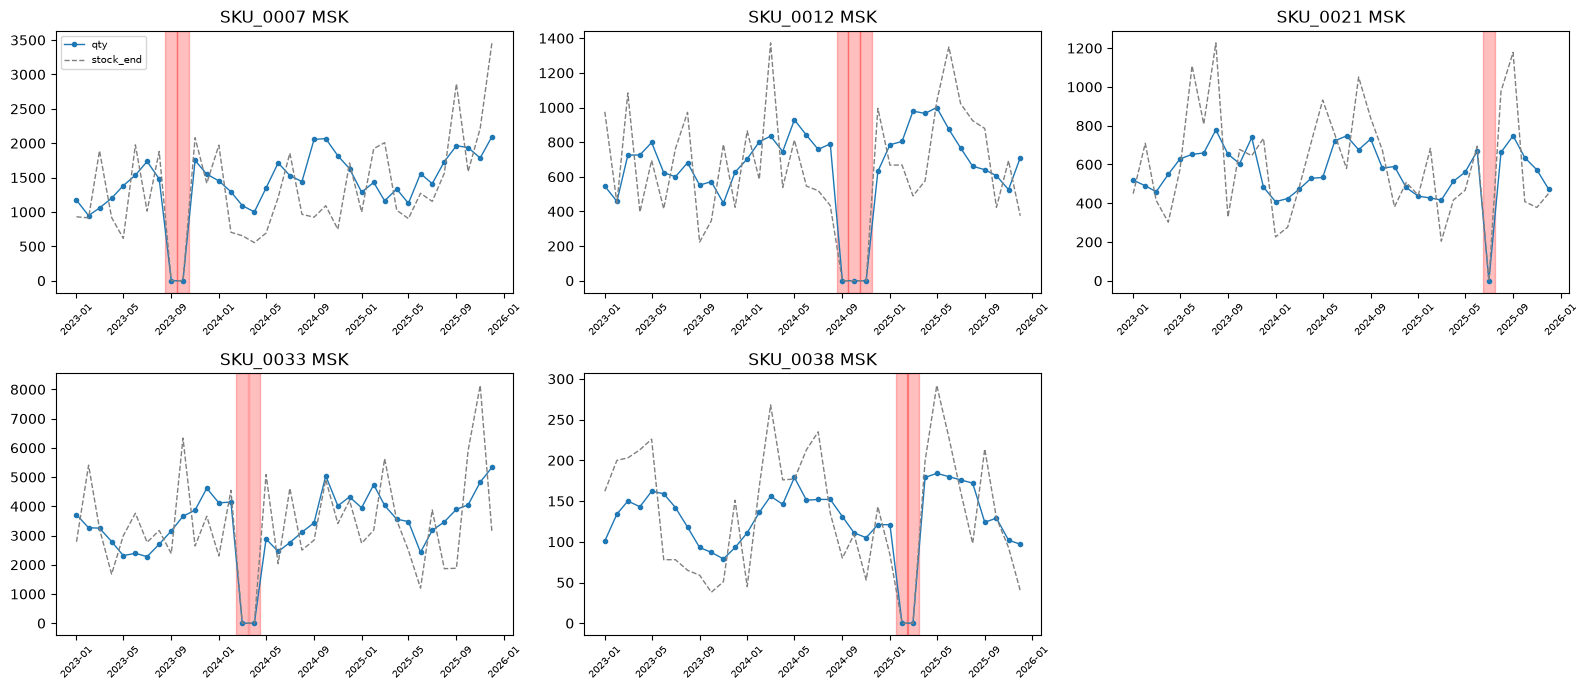

In [66]:
oos_series = oos.series.unique()
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, sname in zip(axes.ravel(), oos_series):
    q = m[m.series == sname]
    ax.plot(q.date, q.qty_fixed, marker='o', ms=3, lw=1, label='qty')
    ax.plot(q.date, q.stock_fixed, lw=1, ls='--', color='gray', label='stock_end')
    for d in q[q.days_out_of_stock > 0].date:
        ax.axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color='red', alpha=.25)
    ax.set_title(sname); ax.tick_params(axis='x', rotation=45, labelsize=7)
axes[0, 0].legend(fontsize=7)
for ax in axes.ravel()[len(oos_series):]: ax.axis('off')
plt.tight_layout(); plt.show()

In [67]:
m['zero_share'] = m.groupby('series').qty_fixed.transform(lambda v: (v <= 0).mean())
m['typ'] = m.groupby('series').qty_fixed.transform('median')
m['stock_cover'] = m.stock_fixed / m.typ

ok = m[(m.days_out_of_stock == 0) & (m.zero_share < 0.3)]
print(ok.stock_cover.describe().round(2))
print(ok.stock_cover.quantile([.01, .05, .95, .99]).round(2).tolist())

display(ok[ok.stock_cover < 0.2][['series', 'period', 'qty_fixed', 'stock_fixed', 'stock_cover']])
display(ok.sort_values('stock_cover').tail(5)[['series', 'period', 'qty_fixed', 'stock_fixed', 'stock_cover']])

count    1297.00
mean       17.74
std       153.30
min         0.00
25%         0.71
50%         1.08
75%         1.46
max      2081.98
Name: stock_cover, dtype: float64
[0.32, 0.42, 2.12, 676.53]


,series,period,qty_fixed,stock_fixed,stock_cover
538,SKU_0014 MSK,2024-06,-8.0,1.0,0.000718


,series,period,qty_fixed,stock_fixed,stock_cover
728,SKU_0018 MSK,2025-04,318.733,456345.0,1595.500315
731,SKU_0018 MSK,2025-07,393.076,516140.0,1804.559122
732,SKU_0018 MSK,2025-08,335.326,539446.0,1886.042934
720,SKU_0018 MSK,2024-08,339.255,567289.0,1983.389273
733,SKU_0018 MSK,2025-09,406.748,595487.0,2081.976785


In [68]:
m['qty_clean'] = m.qty_fixed.where((m.days_out_of_stock == 0) & (m.qty_fixed >= 0))
print(m.qty_clean.isna().sum())
print(m[m.qty_clean.isna()].groupby('series').size())

11
series
SKU_0007 MSK    2
SKU_0012 MSK    3
SKU_0014 MSK    1
SKU_0021 MSK    1
SKU_0033 MSK    2
SKU_0038 MSK    2
dtype: int64


In [69]:
mm = m.merge(promo_calendar_df[['sku', 'period']].assign(flag_promo=True), how='left', on=['sku', 'period'])
mm['flag_oos'] = mm.days_out_of_stock > 0
mm['flag_neg'] = mm.qty_fixed < 0

frames = []
for sname, g in mm.groupby('series'):
    per = pd.period_range(g.period.min(), g.period.max(), freq='M').astype(str)
    f = pd.DataFrame({'series': sname, 'period': per})
    frames.append(f.merge(g[['series', 'period', 'qty_fixed', 'flag_oos', 'flag_neg', 'flag_promo']],
                          on=['series', 'period'], how='left'))
c = pd.concat(frames, ignore_index=True)
c['flag_gap'] = c.qty_fixed.isna()
for col in ['flag_oos', 'flag_neg', 'flag_promo']:
    c[col] = c[col].fillna(False).astype(bool)
c['date'] = pd.to_datetime(c.period)

flags = ['flag_gap', 'flag_oos', 'flag_neg', 'flag_promo']
c['bad'] = c[flags].any(axis=1)
c['qty_clean'] = c.qty_fixed.where(~c.bad)

print(c[flags + ['bad']].sum())
print('строк с несколькими флагами сразу:', (c[flags].sum(axis=1) > 1).sum())

flag_gap       4
flag_oos      10
flag_neg       1
flag_promo     8
bad           23
dtype: int64
строк с несколькими флагами сразу: 0


,series,period,qty,base,uplift,prev_ratio,next_ratio
0,SKU_0001 MSK,2023-11,1172.0,286.0,4.10,1.15,1.17
1,SKU_0001 MSK,2024-11,1159.0,319.0,3.63,1.21,0.99
2,SKU_0006 MSK,2024-03,476.0,133.0,3.58,0.87,1.06
3,SKU_0013 MSK,2025-04,7202.0,1807.5,3.98,1.01,0.99
4,SKU_0020 MSK,2023-06,15629.0,3149.0,4.96,1.08,0.79
5,SKU_0023 MSK,2025-10,5279.0,1561.0,3.38,1.00,1.21
6,SKU_0028 MSK,2023-12,327.0,137.5,2.38,1.25,1.05
7,SKU_0037 MSK,2024-08,1345.0,317.5,4.24,0.96,1.23


count    8.00
mean     3.78
std      0.75
min      2.38
25%      3.53
50%      3.81
75%      4.13
max      4.96
Name: uplift, dtype: float64


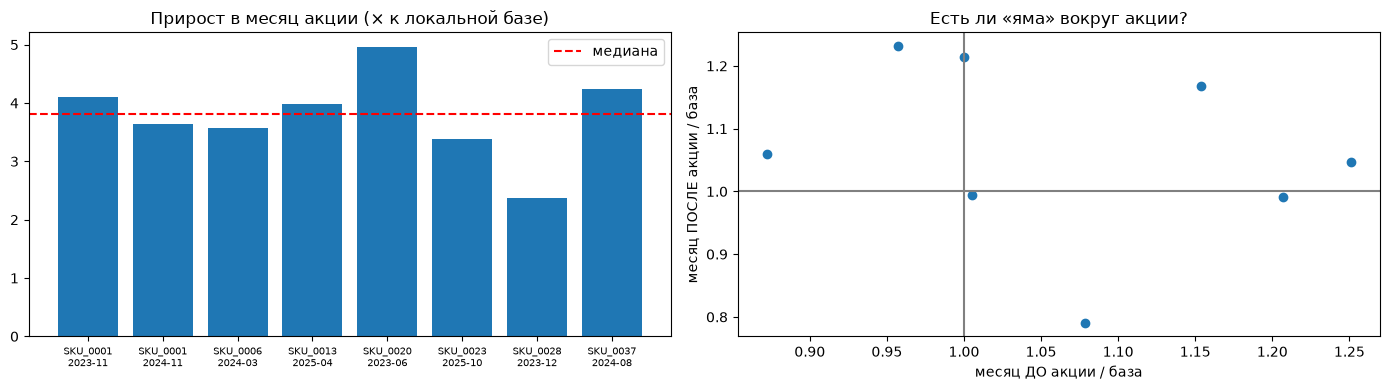

In [70]:
def local_base(v, i, k=3):
    """База = медиана ближайших чистых месяцев (по 3 с каждой стороны), без самого месяца акции."""
    idx = [j for j in range(max(0, i - k), min(len(v), i + k + 1)) if j != i and not np.isnan(v[j])]
    return np.median(v[idx]) if idx else np.nan

rows = []
for sname, g in c.groupby('series'):
    g = g.reset_index(drop=True); v = g.qty_clean.values
    for i in g.index[g.flag_promo]:
        b = local_base(v, i)
        rows.append({'series': sname, 'period': g.period[i], 'qty': g.qty_fixed[i], 'base': b,
                     'uplift': g.qty_fixed[i] / b,
                     'prev_ratio': g.qty_fixed[i - 1] / b if i > 0 else np.nan,
                     'next_ratio': g.qty_fixed[i + 1] / b if i + 1 < len(g) else np.nan})
promo_eff = pd.DataFrame(rows)
display(promo_eff.round(2)); print(promo_eff.uplift.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
lab = promo_eff.series.str.replace(' MSK', '') + '\n' + promo_eff.period
axes[0].bar(lab, promo_eff.uplift)
axes[0].axhline(promo_eff.uplift.median(), color='red', ls='--', label='медиана'); axes[0].legend()
axes[0].set_title('Прирост в месяц акции (× к локальной базе)'); axes[0].tick_params(axis='x', labelsize=7)
axes[1].scatter(promo_eff.prev_ratio, promo_eff.next_ratio)
axes[1].axhline(1, color='gray'); axes[1].axvline(1, color='gray')
axes[1].set_xlabel('месяц ДО акции / база'); axes[1].set_ylabel('месяц ПОСЛЕ акции / база')
axes[1].set_title('Есть ли «яма» вокруг акции?')
plt.tight_layout(); plt.show()

In [74]:
rng = np.random.default_rng(0)

def imp_linear(v): return pd.Series(v).interpolate(limit_direction='both').values

def imp_median(v, k=3):
    o = v.copy()
    for i in np.where(np.isnan(v))[0]:
        idx = [j for j in range(max(0, i - k), min(len(v), i + k + 1)) if not np.isnan(v[j])]
        o[i] = np.median(v[idx]) if idx else np.nan
    return o

def imp_seasonal(v, k=3):
    """Тот же месяц в другие годы, подогнанный по уровню соседних месяцев."""
    o, n = v.copy(), len(v)
    for i in np.where(np.isnan(v))[0]:
        nb = [j for j in range(max(0, i - k), min(n, i + k + 1)) if j != i and not np.isnan(v[j])]
        cands = []
        for s in (-24, -12, 12, 24):
            if 0 <= i + s < n and not np.isnan(v[i + s]):
                pairs = [(v[j], v[j + s]) for j in nb if 0 <= j + s < n and not np.isnan(v[j + s])]
                if len(pairs) >= 2:
                    cands.append(v[i + s] * np.median([a for a, b in pairs]) / np.median([b for a, b in pairs]))
        o[i] = np.median(cands) if cands else (np.median(v[nb]) if nb else np.nan)
    return o

methods = {'linear': imp_linear, 'median±3': imp_median, 'seasonal-analog': imp_seasonal}

elig = [s for s, g in c.groupby('series')
        if g.qty_clean.notna().sum() >= 24 and (g.qty_clean.fillna(1) > 0).mean() > 0.7]
res = []
for sname in elig:
    v0 = c.loc[c.series == sname, 'qty_clean'].values
    for _ in range(40):                                   # прячем 1–3 подряд известных месяца
        L = int(rng.integers(1, 4)); s0 = int(rng.integers(1, len(v0) - L - 1))
        h = [j for j in range(s0, s0 + L) if not np.isnan(v0[j])]
        if not h: continue
        v = v0.copy(); v[h] = np.nan
        for name, f in methods.items():
            p = f(v); res.append((name, L, np.abs(p[h] - v0[h]).sum(), v0[h].sum(), (p[h] - v0[h]).sum()))
r = pd.DataFrame(res, columns=['method', 'L', 'abs', 'act', 'err'])
summ = r.groupby('method').agg(abs=('abs', 'sum'), act=('act', 'sum'), err=('err', 'sum'))
summ['WAPE'] = summ['abs'] / summ.act; summ['bias'] = summ.err / summ.act
display(summ[['WAPE', 'bias']].round(3))
display((r.groupby(['method', 'L'])['abs'].sum() / r.groupby(['method', 'L'])['act'].sum()).unstack().round(3))

,WAPE,bias
method,,
linear,0.145,-0.003
median±3,0.167,-0.012
seasonal-analog,0.159,0.005


L,1,2,3
method,,,
linear,0.129,0.141,0.152
median±3,0.147,0.171,0.170
seasonal-analog,0.149,0.166,0.157


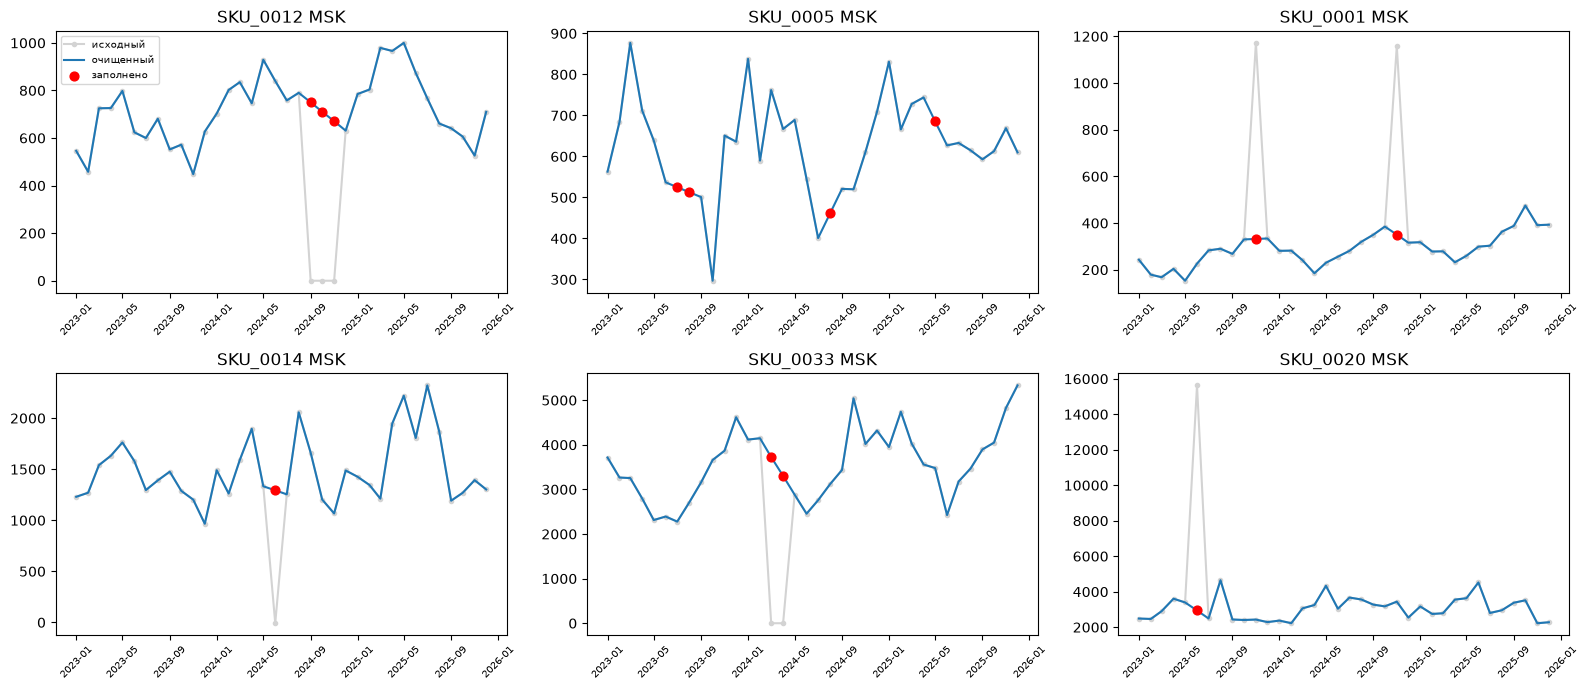

In [75]:
c['qty_base'] = c.groupby('series').qty_clean.transform(lambda s: s.interpolate(limit_direction='both'))
c['imputed'] = c.bad

pick = ['SKU_0012 MSK', 'SKU_0005 MSK', 'SKU_0001 MSK', 'SKU_0014 MSK', 'SKU_0033 MSK', 'SKU_0020 MSK']
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, sname in zip(axes.ravel(), pick):
    q = c[c.series == sname]
    ax.plot(q.date, q.qty_fixed, color='lightgray', marker='o', ms=3, label='исходный')
    ax.plot(q.date, q.qty_base, color='tab:blue', lw=1.5, label='очищенный')
    ax.scatter(q.date[q.imputed], q.qty_base[q.imputed], color='red', s=40, zorder=3, label='заполнено')
    ax.set_title(sname); ax.tick_params(axis='x', rotation=45, labelsize=7)
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

In [76]:
assert c.qty_base.notna().all()
assert (c.qty_base >= 0).all()
assert c.imputed.sum() == 23
assert c[~c.imputed & (c.qty_base != c.qty_fixed)].empty
print('проверки пройдены; заполнено:', c.imputed.sum(), '| рядов:', c.series.nunique(), '| строк:', len(c))

проверки пройдены; заполнено: 23 | рядов: 46 | строк: 1527


In [78]:
LAST_PERIOD = c.period.max()
c = c.sort_values(['series', 'date']).reset_index(drop=True)
c['sku'] = c.series.str.split().str[0]
c['location'] = c.series.str.split().str[1]

rows = []
for sname, g in c.groupby('series'):
    v = g.qty_base.values; n = len(v); nz = v[v > 0]
    rows.append({'series': sname, 'sku': g.sku.iloc[0], 'location': g.location.iloc[0], 'n': n,
                 'start': g.period.iloc[0], 'end': g.period.iloc[-1],
                 'level': np.median(v), 'zero_share': (v == 0).mean(),
                 'adi': n / max((v > 0).sum(), 1),
                 'cv2': (nz.std() / nz.mean()) ** 2 if len(nz) > 1 else np.nan,
                 'vol_12m': v[-12:].sum()})
F = pd.DataFrame(rows).set_index('series')
display(F[['n', 'zero_share', 'adi', 'cv2']].describe().round(2))

,n,zero_share,adi,cv2
count,46.00,46.00,46.00,46.00
mean,33.20,0.09,1.33,0.05
std,8.42,0.24,0.88,0.02
min,5.00,0.00,1.00,0.02
25%,36.00,0.00,1.00,0.04
50%,36.00,0.00,1.00,0.05
75%,36.00,0.00,1.00,0.06
max,36.00,0.75,4.00,0.08


,child,parent,corr_log,ratio_mean,ratio_cv
0,SKU_0003 EKB,SKU_0003 MSK,1.000,0.430,0.001
1,SKU_0008 EKB,SKU_0008 MSK,1.000,0.334,0.001
2,SKU_0017 EKB,SKU_0017 MSK,0.999,0.259,0.010
3,SKU_0022 EKB,SKU_0022 MSK,1.000,0.422,0.000
4,SKU_0027 EKB,SKU_0027 MSK,1.000,0.348,0.001
5,SKU_0034 EKB,SKU_0034 MSK,1.000,0.488,0.001


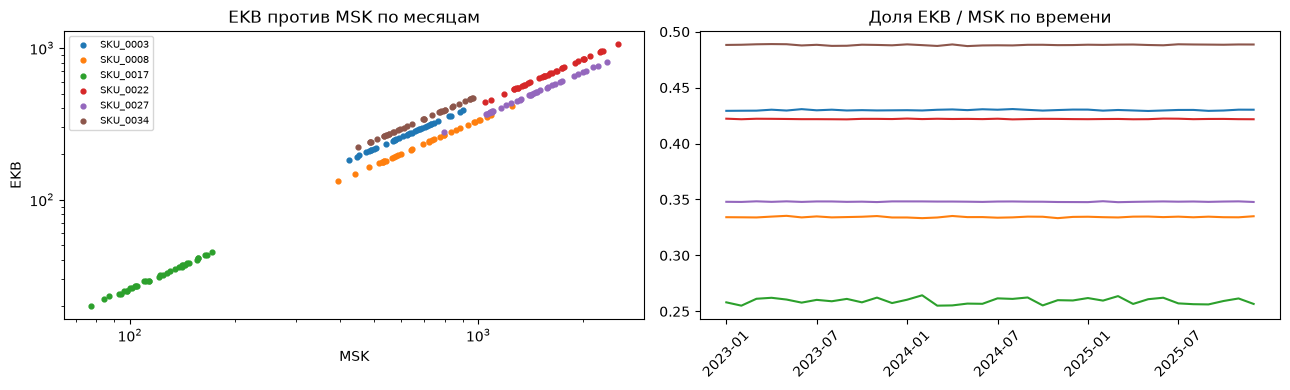

In [79]:
P = c.pivot(index='period', columns='series', values='qty_base')
F['derived_from'] = None; F['share_of_parent'] = np.nan
tw = []
for sku, g in F.groupby('sku'):
    if len(g) < 2: continue
    parent = g.level.idxmax()
    for child in g.index.drop(parent):
        both = P[[parent, child]].dropna(); ratio = both[child] / both[parent]
        corr = np.corrcoef(np.log(both[parent]), np.log(both[child]))[0, 1]
        tw.append({'child': child, 'parent': parent, 'corr_log': corr,
                   'ratio_mean': ratio.mean(), 'ratio_cv': ratio.std() / ratio.mean()})
        if corr > 0.99 and ratio.std() / ratio.mean() < 0.05:
            F.loc[child, ['derived_from', 'share_of_parent']] = [parent, ratio.mean()]
twins = pd.DataFrame(tw); display(twins.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for _, r in twins.iterrows():
    axes[0].scatter(P[r.parent], P[r.child], s=12, label=r.child.split()[0])
    axes[1].plot(P.index, P[r.child] / P[r.parent], label=r.child.split()[0])
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('MSK'); axes[0].set_ylabel('EKB'); axes[0].legend(fontsize=7)
axes[0].set_title('EKB против MSK по месяцам'); axes[1].set_title('Доля EKB / MSK по времени')
axes[1].set_xticks(P.index[::6]); axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

In [80]:
rng = np.random.default_rng(42)

def season_consistency(res, n_years):
    """Средняя попарная корреляция сезонных профилей разных лет."""
    C = np.corrcoef(res.reshape(n_years, 12))
    return C[np.triu_indices(n_years, 1)].mean()


cand = F[(F.n >= 24) & (F.n % 12 == 0) & (F.start.str.endswith('-01')) & (F.zero_share < 0.2)
         & (F['end'] == LAST_PERIOD) & F.derived_from.isna()].index

B = 500; null_pool = []; out = []
for sname in cand:
    y = np.log(P[sname].dropna().values); n = len(y); t = np.arange(n)
    b = np.polyfit(t, y, 1); res = y - np.polyval(b, t)
    se = res.std(ddof=2) / np.sqrt(((t - t.mean()) ** 2).sum())
    obs = season_consistency(res, n // 12)
    null = np.array([season_consistency(rng.permutation(res), n // 12) for _ in range(B)])
    null_pool.append(null)
    out.append({'series': sname, 'trend_pct_yr': np.expm1(12 * b[0]) * 100, 'trend_t': b[0] / se,
                'noise': res.std(ddof=2), 'seas': obs, 'seas_p': (1 + (null >= obs).sum()) / (B + 1)})
S = pd.DataFrame(out).set_index('series'); null_pool = np.concatenate(null_pool)
F = F.join(S)
print('99%-порог "нет сезонности":', np.quantile(null_pool, .99).round(2))
print(S[['seas', 'seas_p', 'trend_t']].describe().round(2))
print((S.seas_p < 0.01).sum(), 'из', len(S), 'рядов с p<0.01')

99%-порог "нет сезонности": 0.44
        seas  seas_p  trend_t
count  29.00   29.00    29.00
mean    0.68    0.01     1.91
std     0.16    0.01     1.56
min     0.29    0.00    -0.93
25%     0.60    0.00     0.85
50%     0.68    0.00     1.77
75%     0.84    0.00     2.90
max     0.93    0.06     5.39
26 из 29 рядов с p<0.01


In [81]:
SEAS_P = 0.01
def assign_segment(r):
    if r['end'] < LAST_PERIOD: return 'discontinued'
    if pd.notna(r.derived_from): return 'derived'
    if r.n < 12: return 'new'
    if r.n < 24: return 'short'
    if r.adi >= 1.32: return 'intermittent' if r.cv2 < 0.49 else 'lumpy'
    return 'regular_seasonal' if r.seas_p < SEAS_P else 'regular_flat'
F['segment'] = F.apply(assign_segment, axis=1)

F['abc'] = F.sku.map(item_master_df.set_index('sku').abc_class)
tot = F.vol_12m.sum()
summary = F.groupby('segment').agg(рядов=('n', 'size'),
                                   доля_объёма_12м=('vol_12m', lambda s: s.sum() / tot)).round(3)
display(summary.sort_values('рядов', ascending=False))
display(pd.crosstab(F.segment, F.abc))
display(F[F.segment.isin(['discontinued', 'new', 'short', 'intermittent', 'lumpy', 'regular_flat'])]
        [['segment', 'n', 'adi', 'cv2', 'seas', 'seas_p']].round(2).sort_values('segment'))

,рядов,доля_объёма_12м
segment,,
regular_seasonal,26,0.728
intermittent,6,0.001
derived,6,0.060
regular_flat,3,0.168
new,3,0.019
discontinued,1,0.017
short,1,0.007


abc,A,B,C
segment,,,
derived,2,2,2
discontinued,0,0,1
intermittent,3,2,1
new,0,0,3
regular_flat,1,0,2
regular_seasonal,8,12,6
short,1,0,0


,segment,n,adi,cv2,seas,seas_p
series,,,,,,
SKU_0011 MSK,discontinued,21,1.00,0.03,NaN,NaN
SKU_0002 MSK,intermittent,36,4.00,0.05,NaN,NaN
SKU_0009 MSK,intermittent,36,3.60,0.07,NaN,NaN
SKU_0015 MSK,intermittent,36,4.00,0.04,NaN,NaN
SKU_0024 MSK,intermittent,36,4.00,0.06,NaN,NaN
SKU_0031 MSK,intermittent,36,2.57,0.04,NaN,NaN
SKU_0040 MSK,intermittent,36,3.00,0.02,NaN,NaN
SKU_0026 MSK,new,5,1.00,0.02,NaN,NaN
SKU_0029 MSK,new,5,1.00,0.03,NaN,NaN


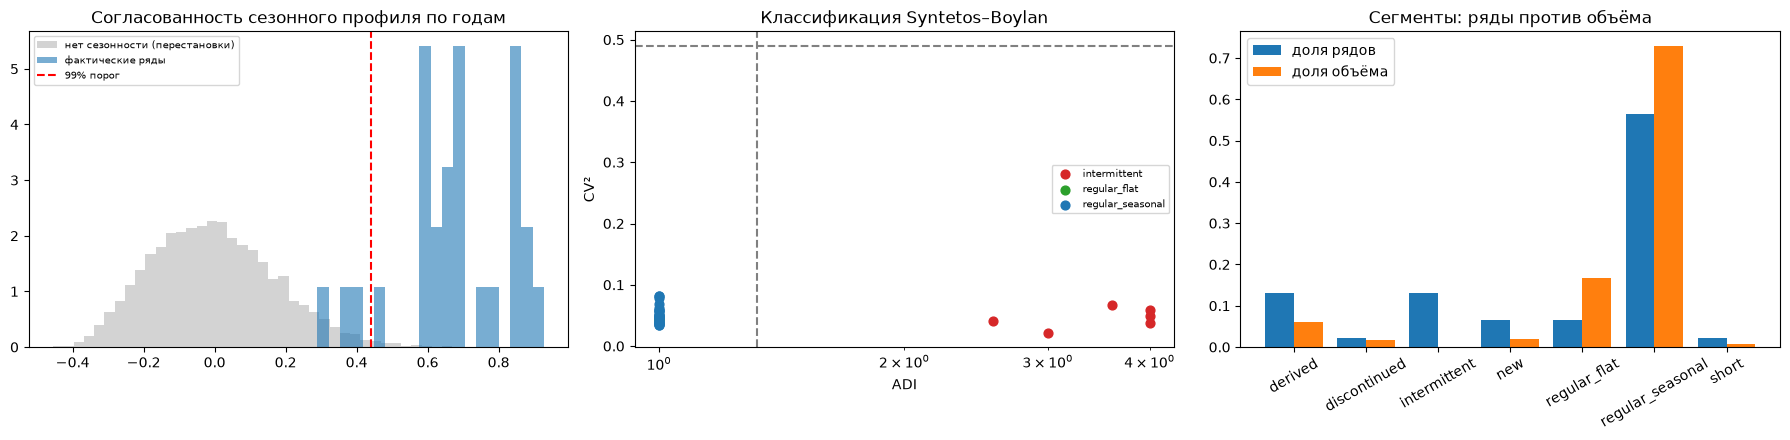

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
ax = axes[0]
ax.hist(null_pool, bins=40, density=True, color='lightgray', label='нет сезонности (перестановки)')
ax.hist(S.seas, bins=20, density=True, alpha=.6, label='фактические ряды')
ax.axvline(np.quantile(null_pool, .99), color='red', ls='--', label='99% порог')
ax.set_title('Согласованность сезонного профиля по годам'); ax.legend(fontsize=7)

ax = axes[1]
seg_col = {'intermittent': 'tab:red', 'lumpy': 'tab:purple', 'regular_seasonal': 'tab:blue', 'regular_flat': 'tab:green'}
for sg, g in F[F.segment.isin(seg_col)].groupby('segment'):
    ax.scatter(g.adi, g.cv2, label=sg, color=seg_col[sg], s=40)
ax.axvline(1.32, color='gray', ls='--'); ax.axhline(0.49, color='gray', ls='--')
ax.set_xscale('log'); ax.legend(fontsize=7); ax.set_xlabel('ADI'); ax.set_ylabel('CV²')
ax.set_title('Классификация Syntetos–Boylan')

ax = axes[2]
x = np.arange(len(summary))
ax.bar(x - .2, summary.рядов / summary.рядов.sum(), .4, label='доля рядов')
ax.bar(x + .2, summary.доля_объёма_12м, .4, label='доля объёма')
ax.set_xticks(x); ax.set_xticklabels(summary.index, rotation=30); ax.legend()
ax.set_title('Сегменты: ряды против объёма')
plt.tight_layout(); plt.show()

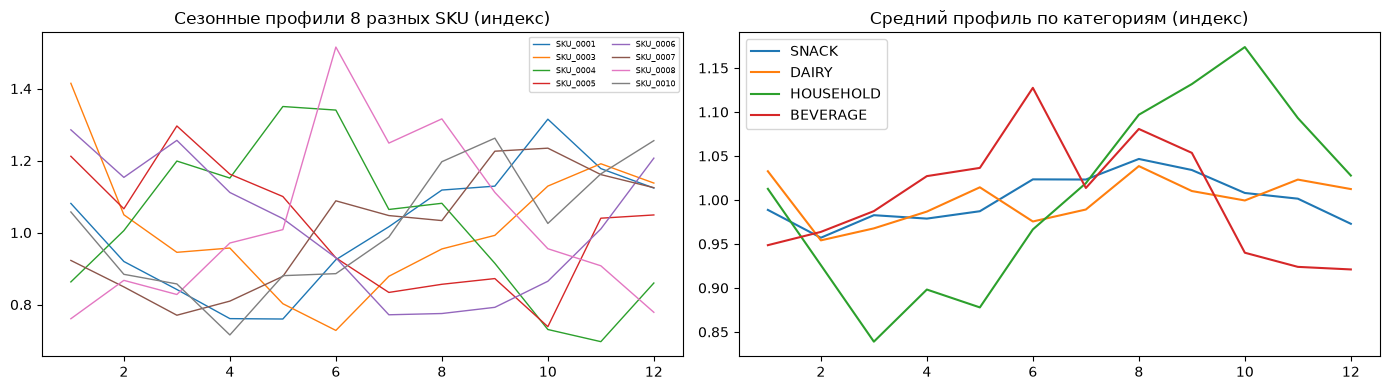

средняя корреляция профилей разных SKU: 0.01
амплитуда профиля (max/min), медиана: 1.76


In [83]:
cat = item_master_df.set_index('sku').category
reg = F[F.segment.isin(['regular_seasonal', 'regular_flat'])].index

def profile(sname):
    y = np.log(P[sname].dropna().values); t = np.arange(len(y))
    r = y - np.polyval(np.polyfit(t, y, 1), t)
    return pd.Series(r.reshape(-1, 12).mean(axis=0), index=range(1, 13))
Pr = pd.DataFrame({s: profile(s) for s in reg})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for s in list(reg[:8]): axes[0].plot(Pr.index, np.exp(Pr[s]), lw=1, label=s.split()[0])
axes[0].set_title('Сезонные профили 8 разных SKU (индекс)'); axes[0].legend(fontsize=6, ncol=2)
Pcat = pd.DataFrame({k: np.exp(Pr[[s for s in reg if cat[s.split()[0]] == k]].mean(axis=1)) for k in cat.unique()})
Pcat.plot(ax=axes[1]); axes[1].set_title('Средний профиль по категориям (индекс)')
plt.tight_layout(); plt.show()

corr_all = Pr.corr().values[np.triu_indices(len(reg), 1)]
print('средняя корреляция профилей разных SKU: %.2f' % corr_all.mean())
print('амплитуда профиля (max/min), медиана: %.2f' % np.median(np.exp(Pr.max()) / np.exp(Pr.min())))

In [84]:
H, MIN_TRAIN, M = 3, 24, 12

def f_naive(train, h):          # последнее значение
    return np.repeat(train[-1], h)
def f_snaive(train, h):         # тот же месяц год назад
    return np.array([train[len(train) - M + (i % M)] for i in range(h)])
def f_ma12(train, h):           # среднее за последние 12 месяцев, без сезонности
    return np.repeat(train[-M:].mean(), h)

METHODS = {'naive': f_naive, 'seasonal_naive': f_snaive, 'ma12': f_ma12}

In [85]:
def backtest(c, F, methods, segments, H=3, min_train=24):
    recs = []
    for sname in F.index[F.segment.isin(segments)]:
        g = c[c.series == sname].sort_values('date')
        y, imp, per = g.qty_base.values, g.imputed.values, g.period.values
        for T in range(min_train, len(y) - H + 1):          # T = длина обучающей части
            train = y[:T]
            scale = np.abs(train[M:] - train[:-M]).mean()    # знаменатель MASE
            for name, f in methods.items():
                fc = f(train, H)
                for h in range(H):
                    if imp[T + h]:                           # заполненный факт не оцениваем
                        continue
                    recs.append((sname, F.loc[sname, 'segment'], name, per[T - 1], h + 1,
                                 per[T + h], y[T + h], fc[h], scale))
    bt = pd.DataFrame(recs, columns=['series', 'segment', 'method', 'origin', 'h', 'target',
                                     'actual', 'fc', 'scale'])
    bt['err'] = bt.fc - bt.actual
    bt['abs_err'] = bt.err.abs()
    return bt

bt = backtest(c, F, METHODS, ['regular_seasonal', 'regular_flat', 'intermittent'], H, MIN_TRAIN)
print(bt.shape, '| origins:', bt.origin.nunique(), '| рядов:', bt.series.nunique())
print('origins:', bt.origin.min(), '…', bt.origin.max())
reg, inter = bt[bt.segment.str.startswith('regular')], bt[bt.segment == 'intermittent']

(3099, 11) | origins: 10 | рядов: 35
origins: 2024-12 … 2025-09


In [86]:
def metrics(d):
    sc = (d.abs_err / d.scale).groupby(d.series).mean()
    return pd.Series({'WAPE': d.abs_err.sum() / d.actual.sum(),
                      'bias': d.err.sum() / d.actual.sum(),
                      'MASE': sc.mean(), 'n': len(d)})

display(reg.groupby('method').apply(metrics).round(3))
display(bt.groupby(['segment', 'method']).apply(metrics).round(3))
display(reg[reg.origin == '2024-12'].groupby('method').apply(metrics).round(3))
display(reg.groupby(['method', 'h']).apply(metrics)[['WAPE', 'bias']].unstack().round(3))

,WAPE,bias,MASE,n
method,,,,
ma12,0.181,-0.027,1.359,853.0
naive,0.203,-0.004,1.416,853.0
seasonal_naive,0.163,-0.058,1.078,853.0


WAPE   bias   MASE      n
segment          method                                    
intermittent     ma12            1.453  0.131  1.141  180.0
                 naive           1.426  0.009  1.189  180.0
                 seasonal_naive  1.705  0.339  1.234  180.0
regular_flat     ma12            0.179 -0.038  1.266   90.0
                 naive           0.223 -0.008  1.454   90.0
                 seasonal_naive  0.205 -0.045  1.405   90.0
regular_seasonal ma12            0.181 -0.024  1.370  763.0
                 naive           0.198 -0.003  1.412  763.0
                 seasonal_naive  0.153 -0.062  1.041  763.0

,WAPE,bias,MASE,n
method,,,,
ma12,0.167,-0.048,1.290,85.0
naive,0.140,0.004,1.128,85.0
seasonal_naive,0.162,-0.099,1.043,85.0


WAPE                 bias              
h                   1      2      3      1      2      3
method                                                  
ma12            0.174  0.180  0.187 -0.024 -0.026 -0.031
naive           0.160  0.199  0.249 -0.002 -0.002 -0.008
seasonal_naive  0.164  0.163  0.163 -0.065 -0.059 -0.051

                  sum  count
seg                         
regular_flat        1      3
regular_seasonal   22     26
топ-5 рядов = 45% объёма и 50% абсолютной ошибки ['SKU_0025 MSK', 'SKU_0020 MSK', 'SKU_0033 MSK', 'SKU_0010 MSK', 'SKU_0014 MSK']
у seasonal_naive bias<0 у 24 из 29 рядов; корреляция bias с трендом: -0.74


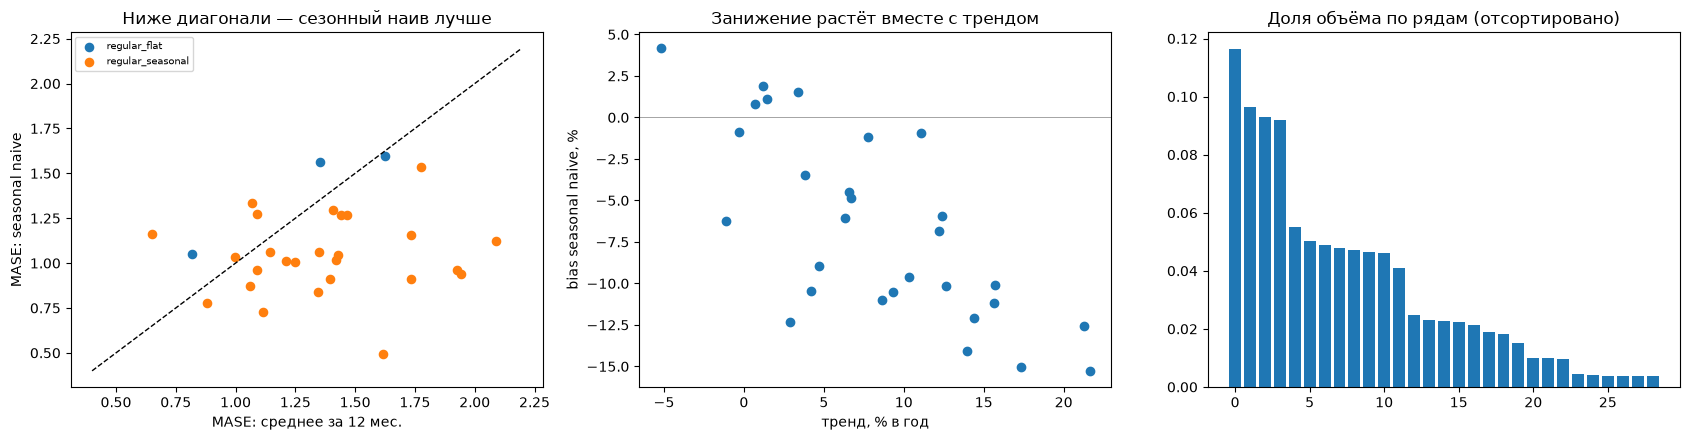

In [87]:
mase_ps = (bt.abs_err / bt.scale).groupby([bt.series, bt.method]).mean().unstack()
mase_ps['seg'] = F.loc[mase_ps.index, 'segment']
r = mase_ps[mase_ps.seg.str.startswith('regular')]
print((r.seasonal_naive < r.ma12).groupby(r.seg).agg(['sum', 'count']))

sn = reg[reg.method == 'seasonal_naive']
bias_ps = sn.err.groupby(sn.series).sum() / sn.actual.groupby(sn.series).sum()
vol = reg.drop_duplicates(['series', 'target']).groupby('series').actual.sum().sort_values(ascending=False)
err5 = sn.abs_err.groupby(sn.series).sum().sort_values(ascending=False)
print('топ-5 рядов = %.0f%% объёма и %.0f%% абсолютной ошибки' %
      (100 * vol.head(5).sum() / vol.sum(), 100 * err5.head(5).sum() / err5.sum()), list(err5.head(5).index))
print('у seasonal_naive bias<0 у %d из %d рядов; корреляция bias с трендом: %.2f' %
      ((bias_ps < 0).sum(), len(bias_ps), np.corrcoef(bias_ps, F.loc[bias_ps.index, 'trend_pct_yr'])[0, 1]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ax = axes[0]
for sg, g in r.groupby('seg'): ax.scatter(g.ma12, g.seasonal_naive, label=sg, s=35)
lim = [0.4, r[['ma12', 'seasonal_naive']].max().max() * 1.05]; ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlabel('MASE: среднее за 12 мес.'); ax.set_ylabel('MASE: seasonal naive'); ax.legend(fontsize=7)
ax.set_title('Ниже диагонали — сезонный наив лучше')
ax = axes[1]
ax.scatter(F.loc[bias_ps.index, 'trend_pct_yr'], bias_ps * 100)
ax.axhline(0, color='gray', lw=.5); ax.set_xlabel('тренд, % в год'); ax.set_ylabel('bias seasonal naive, %')
ax.set_title('Занижение растёт вместе с трендом')
ax = axes[2]
ax.bar(range(len(vol)), (vol / vol.sum()).values); ax.set_title('Доля объёма по рядам (отсортировано)')
plt.tight_layout(); plt.show()

РЕГУЛЯРНЫЕ  k*: MAPE=1.04, WAPE=1.05, RMSE=1.02
ПРЕРЫВИСТЫЕ k*: MAPE=2.00, MAE=0.00, RMSE=0.80 | нулей в фактах: 72%


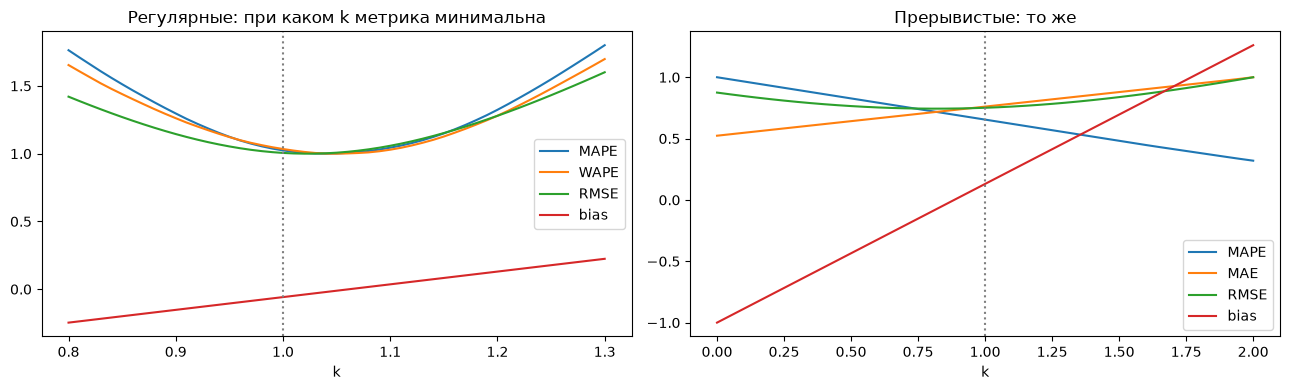

In [88]:
def scan(d, ks, base):
    """Умножаем прогноз на k и смотрим, при каком k каждая метрика минимальна."""
    rows = []
    for k in ks:
        e = base * k - d.actual; ae = e.abs(); pos = d.actual > 0
        rows.append({'k': k, 'MAPE': (ae[pos] / d.actual[pos]).mean(), 'WAPE': ae.sum() / d.actual.sum(),
                     'MAE': ae.mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'bias': e.sum() / d.actual.sum()})
    return pd.DataFrame(rows).set_index('k')

kr = scan(sn, np.round(np.arange(0.8, 1.31, 0.01), 2), sn.fc)
im12 = inter[inter.method == 'ma12']
ki = scan(im12, np.round(np.arange(0, 2.01, 0.05), 2), im12.fc)
print('РЕГУЛЯРНЫЕ  k*: MAPE=%.2f, WAPE=%.2f, RMSE=%.2f' % (kr.MAPE.idxmin(), kr.WAPE.idxmin(), kr.RMSE.idxmin()))
print('ПРЕРЫВИСТЫЕ k*: MAPE=%.2f, MAE=%.2f, RMSE=%.2f | нулей в фактах: %.0f%%' %
      (ki.MAPE.idxmin(), ki.MAE.idxmin(), ki.RMSE.idxmin(), 100 * (im12.actual == 0).mean()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col in ['MAPE', 'WAPE', 'RMSE']: axes[0].plot(kr.index, kr[col] / kr[col].min(), label=col)
axes[0].plot(kr.index, kr.bias, label='bias'); axes[0].axvline(1, color='gray', ls=':'); axes[0].legend()
axes[0].set_title('Регулярные: при каком k метрика минимальна'); axes[0].set_xlabel('k')
for col in ['MAPE', 'MAE', 'RMSE']: axes[1].plot(ki.index, ki[col] / ki[col].max(), label=col)
axes[1].plot(ki.index, ki.bias, label='bias'); axes[1].axvline(1, color='gray', ls=':'); axes[1].legend()
axes[1].set_title('Прерывистые: то же'); axes[1].set_xlabel('k')
plt.tight_layout(); plt.show()